# 06 Template Studi Kasus

## Tujuan notebook ini

Dalam notebook ini, Anda akan menerapkan **seluruh workflow analitik** dari notebook sebelumnya dalam satu studi kasus terpadu:

1. **Rumusan masalah** → Definisikan pertanyaan riset
2. **Eksplorasi data** → Pahami struktur & kualitas data
3. **Statistik deskriptif** → Ringkas data dengan metrik
4. **Visualisasi** → Buat chart untuk pola
5. **Analisis inferensial** → Regresi atau test statistik
6. **Interpretasi & limitasi** → Jelaskan hasil dengan hati-hati
7. **Dokumentasi AI** → Catat bantuan AI yang diterima

---

**Format notebook ini:**
- Bagian dengan teks penjelasan
- Bagian dengan **[ANDA TULIS DI SINI]** untuk input Anda
- Bagian dengan kode template siap pakai (ubah sesuai kebutuhan)

### Penanda Sel Kode
- `# RUN-NOW`: dapat langsung dijalankan.
- `# LEARNER-TASK`: ubah bagian bertanda [UBAH]/[ANDA TULIS], lalu jalankan.

## BAGIAN 1: RUMUSAN MASALAH

Definisikan pertanyaan riset Anda dengan jelas.

### Judul studi kasus
[ANDA TULIS DI SINI: Berikan judul deskriptif]

Contoh: "Pengaruh Kehadiran Kelas dan Akses Internet terhadap Prestasi Akademik Mahasiswa"

In [41]:
# LEARNER-TASK: Edit sesuai instruksi, lalu jalankan.
case_study_title = "[Pengaruh IP Sebelumnya dan Jumlah Jam Belajar Terhadap Nilai Akhir Mahasiswa]"
print(f"STUDI KASUS: {case_study_title}")

STUDI KASUS: [Pengaruh IP Sebelumnya dan Jumlah Jam Belajar Terhadap Nilai Akhir Mahasiswa]


### Pertanyaan penelitian utama

[ANDA TULIS DI SINI: Apa pertanyaan penelitian Anda? Gunakan format: "Apakah/Bagaimana..."]

Contoh:
- "Apakah tingkat kehadiran mahasiswa memprediksi nilai akhir mereka?"
- "Bagaimana akses internet mempengaruhi perbedaan prestasi antar program?"

Pertanyaan Anda:

Bagaimana pengaruh IP sebelumnya terhadap nilai akhir mahasiswa?

Bagaimana pengaruh Jumlah jam belajar terhadap nilai akhir mahasiswa?

In [42]:
# LEARNER-TASK: Edit sesuai instruksi, lalu jalankan.
research_question = "[Bagaimana pengaruh IP sebelumnya terhadap nilai akhir mahasiswa?,\n Bagaimana pengaruh jumlah jam belajar terhadap nilai akhir mahasiswa? ]"
print(f"Pertanyaan Penelitian: {research_question}")

Pertanyaan Penelitian: [Bagaimana pengaruh IP sebelumnya terhadap nilai akhir mahasiswa?,
 Bagaimana pengaruh jumlah jam belajar terhadap nilai akhir mahasiswa? ]


### Variabel yang relevan

[ANDA TULIS DI SINI: Daftar variabel]

Contoh:
- **Variabel outcome**: final_grade (nilai akhir mahasiswa)
- **Variabel prediktor utama**: attendance_rate (tingkat kehadiran)
- **Variabel kontrol**: previous_gpa, program, internet_access

In [43]:
# LEARNER-TASK: Edit sesuai instruksi, lalu jalankan.
outcome_var = "[VARIABEL OUTCOME: final_grade]"  # Variabel hasil yang ingin Anda prediksi
main_predictors = ["[VARIABEL PREDIKTOR UTAMA: previous_gpa, study_hours_per_week]"]  # Bisa lebih dari satu
control_vars = ["[VARIABEL KONTROL: , attendance_rate, ]"]  # Optional

print(f"Outcome: {outcome_var}")
print(f"Prediktor: {main_predictors}")
print(f"Kontrol: {control_vars}")

Outcome: [VARIABEL OUTCOME: final_grade]
Prediktor: ['[VARIABEL PREDIKTOR UTAMA: previous_gpa, study_hours_per_week]']
Kontrol: ['[VARIABEL KONTROL: , attendance_rate, ]']


## BAGIAN 2: SETUP & LOAD DATA

In [44]:
# RUN-NOW: Jalankan sel ini apa adanya.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.linear_model import LinearRegression

# Muat data bersih — dengan fallback untuk berbagai working directory
candidate_paths = [
    Path("data/processed/student_performance_cleaned.csv"),
    Path("../data/processed/student_performance_cleaned.csv"),
    Path("/workspaces/metpen-ai-lab/data/processed/student_performance_cleaned.csv"),
]

cleaned_file = next((p for p in candidate_paths if p.exists()), None)
if cleaned_file is None:
    raise FileNotFoundError(
        "❌ File data bersih tidak ditemukan.\n"
        "Anda perlu menjalankan notebook 02 (02_data_quality_cleaning.ipynb) terlebih dahulu\n"
        "untuk membuat file: data/processed/student_performance_cleaned.csv"
    )

df = pd.read_csv(cleaned_file)

print(f"✓ Data dimuat dari: {cleaned_file.resolve()}")
print(f"✓ Data dimuat: {df.shape[0]} baris × {df.shape[1]} kolom")
print(f"✓ Ready untuk analisis")

✓ Data dimuat dari: /workspaces/metpen-ai-lab/notebooks/data/processed/student_performance_cleaned.csv
✓ Data dimuat: 2000 baris × 20 kolom
✓ Ready untuk analisis


## BAGIAN 3: DESKRIPSI DATASET

Deskripsikan karakteristik umum dataset Anda.

In [45]:
# RUN-NOW: Jalankan sel ini apa adanya.
print("PROFIL DATASET KAMI")
print("="*50)
print(f"Ukuran sampel (N): {df.shape[0]} mahasiswa")
print(f"Jumlah variabel: {df.shape[1]}")
print(f"\nProgram studi:")
print(df['program'].value_counts())
print(f"\nTahun cohort:")
print(df['cohort_year'].value_counts())
print(f"\nTingkat lulus: {(df['passed'].sum() / len(df) * 100):.1f}%")

PROFIL DATASET KAMI
Ukuran sampel (N): 2000 mahasiswa
Jumlah variabel: 20

Program studi:
program
Education           453
Computer Science    435
Economics           415
Psychology          399
Public Health       298
Name: count, dtype: int64

Tahun cohort:
cohort_year
2022    600
2023    579
2024    413
2021    408
Name: count, dtype: int64

Tingkat lulus: 99.9%


## BAGIAN 4: PEMERIKSAAN KUALITAS DATA

In [46]:
# RUN-NOW: Jalankan sel ini apa adanya.
# Periksa missing values
missing = df.isnull().sum()
print("Nilai hilang:")
if missing.sum() > 0:
    print(missing[missing > 0])
else:
    print("✓ Tidak ada nilai hilang")

# Periksa duplikat
print(f"\nDuplikat baris: {df.duplicated().sum()}")

Nilai hilang:
✓ Tidak ada nilai hilang

Duplikat baris: 0


## BAGIAN 5: STATISTIK DESKRIPTIF OUTCOME VARIABLE

In [47]:
# LEARNER-TASK: Edit sesuai instruksi, lalu jalankan.
# Template: Ganti 'final_grade' dengan outcome_var Anda
outcome_analysis_var = 'final_grade'  # [UBAH INI]

print(f"STATISTIK DESKRIPTIF: {outcome_analysis_var}")
print("="*50)
print(f"Mean:     {df[outcome_analysis_var].mean():.2f}")
print(f"Median:   {df[outcome_analysis_var].median():.2f}")
print(f"Std Dev:  {df[outcome_analysis_var].std():.2f}")
print(f"Min:      {df[outcome_analysis_var].min():.2f}")
print(f"Max:      {df[outcome_analysis_var].max():.2f}")
print(f"IQR:      {df[outcome_analysis_var].quantile(0.75) - df[outcome_analysis_var].quantile(0.25):.2f}")

# Interpretasi
print(f"\n📝 Interpretasi:")
print("""
Nilai ujian mahasiswa memiliki rata-rata sebesar 86,91 dengan median 87,34,
yang menunjukkan distribusi data relatif simetris. Standar deviasi sebesar
7,28 mengindikasikan variasi nilai yang tidak terlalu besar di sekitar
rata-rata. Nilai ujian berkisar antara 57,80 hingga 100,00 dengan IQR sebesar
10,08, yang menunjukkan bahwa sebagian besar mahasiswa memperoleh nilai dalam
rentang yang cukup konsisten.
""")

STATISTIK DESKRIPTIF: final_grade
Mean:     86.91
Median:   87.34
Std Dev:  7.28
Min:      57.80
Max:      100.00
IQR:      10.08

📝 Interpretasi:

Nilai ujian mahasiswa memiliki rata-rata sebesar 86,91 dengan median 87,34,
yang menunjukkan distribusi data relatif simetris. Standar deviasi sebesar
7,28 mengindikasikan variasi nilai yang tidak terlalu besar di sekitar
rata-rata. Nilai ujian berkisar antara 57,80 hingga 100,00 dengan IQR sebesar
10,08, yang menunjukkan bahwa sebagian besar mahasiswa memperoleh nilai dalam
rentang yang cukup konsisten.



## BAGIAN 6: VISUALISASI UTAMA

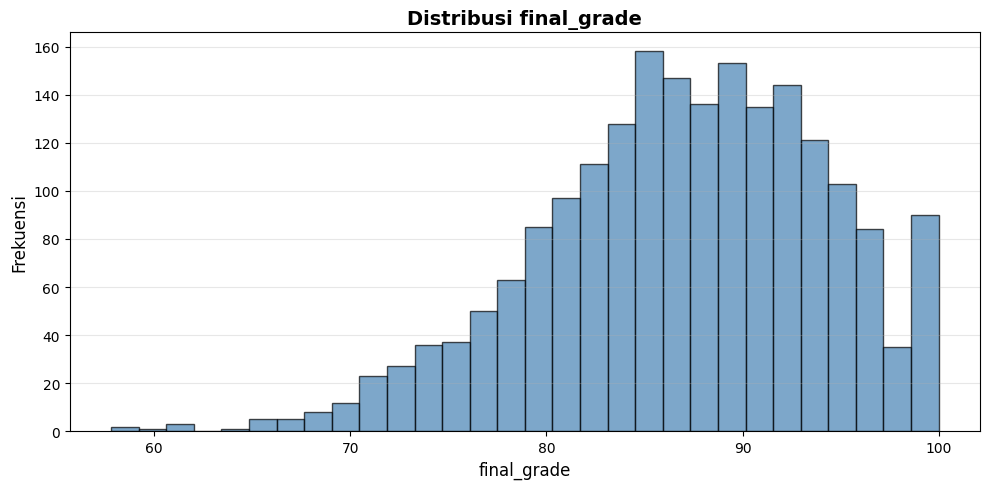


📝 Interpretasi histogram:

Berdasarkan histogram tersebut, distribusi data bersifat skewed left 
(miring ke kiri) karena ekor distribusi memanjang ke arah nilai rendah, 
sementara sebagian besar data terkonsentrasi pada rentang nilai tinggi 
sekitar 80–95. Terdapat indikasi outlier pada nilai di bawah 65 yang 
jumlahnya relatif sedikit dan terpisah dari distribusi utama. Selain itu, 
terlihat adanya lonjakan frekuensi yang cukup tinggi pada batas maksimum 
nilai 100 yang dapat mengindikasikan adanya penumpukan data pada nilai tertinggi.



In [48]:
# LEARNER-TASK: Edit sesuai instruksi, lalu jalankan.
# Histogram outcome
plt.figure(figsize=(10, 5))
plt.hist(df[outcome_analysis_var], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
plt.xlabel(outcome_analysis_var, fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)
plt.title(f'Distribusi {outcome_analysis_var}', fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("\n📝 Interpretasi histogram:")
print("""
Berdasarkan histogram tersebut, distribusi data bersifat skewed left 
(miring ke kiri) karena ekor distribusi memanjang ke arah nilai rendah, 
sementara sebagian besar data terkonsentrasi pada rentang nilai tinggi 
sekitar 80–95. Terdapat indikasi outlier pada nilai di bawah 65 yang 
jumlahnya relatif sedikit dan terpisah dari distribusi utama. Selain itu, 
terlihat adanya lonjakan frekuensi yang cukup tinggi pada batas maksimum 
nilai 100 yang dapat mengindikasikan adanya penumpukan data pada nilai tertinggi.
""")

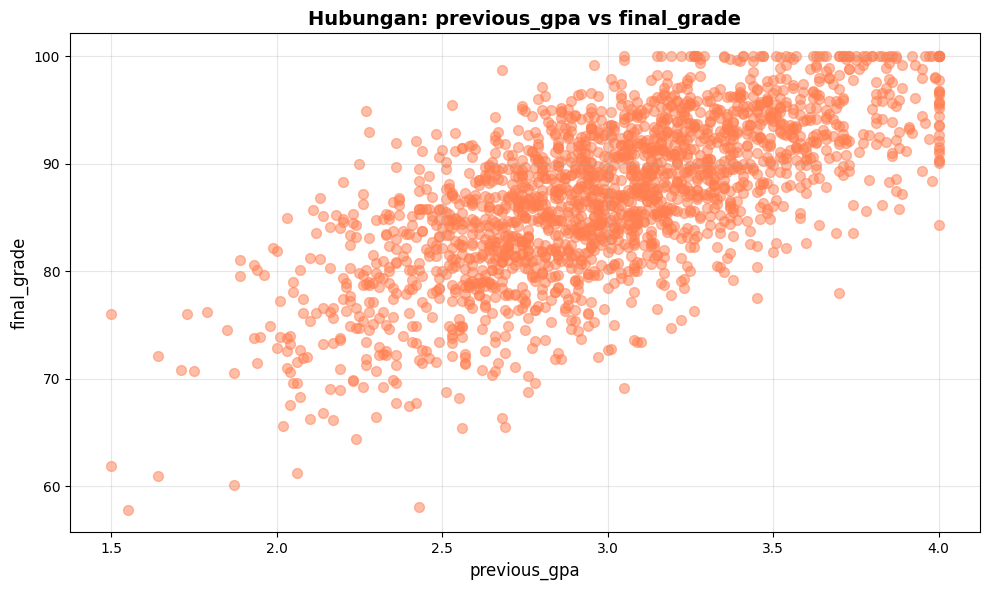

Korelasi Pearson: 0.682

📝 Interpretasi scatter plot:

Scatter plot menunjukkan adanya hubungan positif antara Previous GPA dan Final Grade,
di mana mahasiswa dengan IP sebelumnya yang lebih tinggi cenderung memperoleh nilai
ujian yang lebih baik. Nilai korelasi Pearson sebesar 0,682 menunjukkan hubungan
positif dengan kekuatan sedang hingga kuat. Meskipun demikian, sebaran titik yang
masih cukup luas mengindikasikan bahwa nilai ujian juga dipengaruhi oleh faktor lain
selain IP sebelumnya.



In [49]:
# LEARNER-TASK: Edit sesuai instruksi, lalu jalankan.
# Scatter plot: Prediktor utama vs Outcome
# [UBAH 'attendance_rate' dan 'final_grade' dengan variabel pilihan Anda]
pred_var = 'previous_gpa'  # [UBAH]
outcome_var_plot = 'final_grade'  # [UBAH]

plt.figure(figsize=(10, 6))
plt.scatter(df[pred_var], df[outcome_var_plot], alpha=0.5, s=50, color='coral')
plt.xlabel(pred_var, fontsize=12)
plt.ylabel(outcome_var_plot, fontsize=12)
plt.title(f'Hubungan: {pred_var} vs {outcome_var_plot}', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

corr_scatter = df[pred_var].corr(df[outcome_var_plot])
print(f"Korelasi Pearson: {corr_scatter:.3f}")
print("\n📝 Interpretasi scatter plot:")
print("""
Scatter plot menunjukkan adanya hubungan positif antara Previous GPA dan Final Grade,
di mana mahasiswa dengan IP sebelumnya yang lebih tinggi cenderung memperoleh nilai
ujian yang lebih baik. Nilai korelasi Pearson sebesar 0,682 menunjukkan hubungan
positif dengan kekuatan sedang hingga kuat. Meskipun demikian, sebaran titik yang
masih cukup luas mengindikasikan bahwa nilai ujian juga dipengaruhi oleh faktor lain
selain IP sebelumnya.
""")

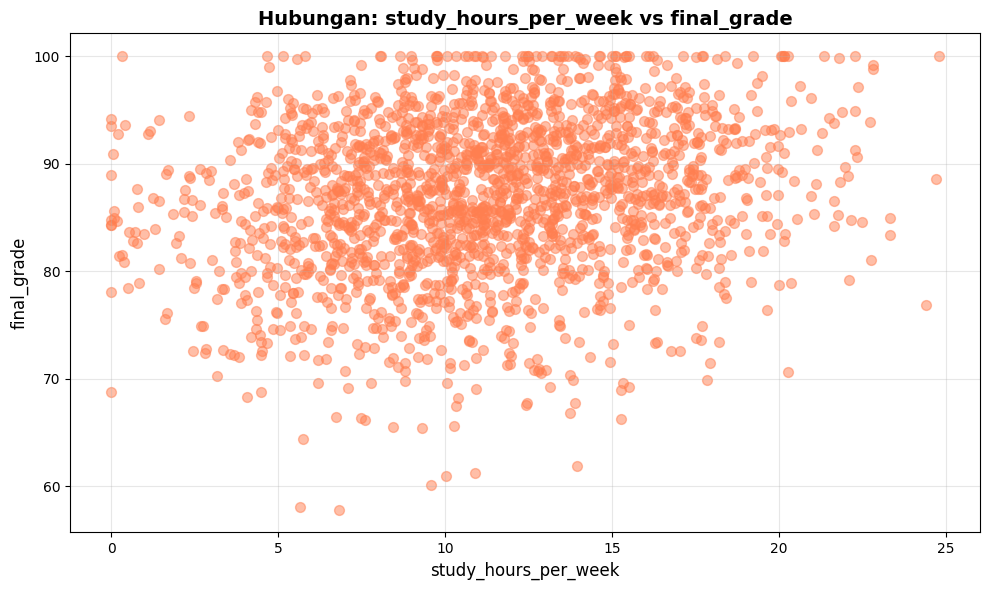

Korelasi Pearson: 0.207

📝 Interpretasi scatter plot:

Scatter plot menunjukkan adanya hubungan positif antara study hours dan nilai
akhir mahasiswa. Nilai korelasi Pearson sebesar 0,207 menunjukkan bahwa
hubungan antara kedua variabel tergolong lemah. Mahasiswa yang memiliki jam
belajar lebih tinggi cenderung memperoleh nilai akhir yang lebih baik, namun
pengaruhnya tidak terlalu kuat. Sebaran titik yang cukup luas mengindikasikan
bahwa nilai akhir juga dipengaruhi oleh faktor-faktor lain di luar jumlah jam
belajar.



In [50]:
# LEARNER-TASK: Edit sesuai instruksi, lalu jalankan.
# Scatter plot: Prediktor utama vs Outcome
# [UBAH 'attendance_rate' dan 'final_grade' dengan variabel pilihan Anda]
pred_var = 'study_hours_per_week'  # [UBAH]
outcome_var_plot = 'final_grade'  # [UBAH]

plt.figure(figsize=(10, 6))
plt.scatter(df[pred_var], df[outcome_var_plot], alpha=0.5, s=50, color='coral')
plt.xlabel(pred_var, fontsize=12)
plt.ylabel(outcome_var_plot, fontsize=12)
plt.title(f'Hubungan: {pred_var} vs {outcome_var_plot}', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

corr_scatter = df[pred_var].corr(df[outcome_var_plot])
print(f"Korelasi Pearson: {corr_scatter:.3f}")
print("\n📝 Interpretasi scatter plot:")

\
print("""
Scatter plot menunjukkan adanya hubungan positif antara study hours dan nilai
akhir mahasiswa. Nilai korelasi Pearson sebesar 0,207 menunjukkan bahwa
hubungan antara kedua variabel tergolong lemah. Mahasiswa yang memiliki jam
belajar lebih tinggi cenderung memperoleh nilai akhir yang lebih baik, namun
pengaruhnya tidak terlalu kuat. Sebaran titik yang cukup luas mengindikasikan
bahwa nilai akhir juga dipengaruhi oleh faktor-faktor lain di luar jumlah jam
belajar.
""")

## BAGIAN 7: PEMILIHAN METODE ANALISIS

### Metode yang Anda pilih

[ANDA TULIS DI SINI: Metode apa yang paling cocok?]

Pilihan:
- **Regresi Linear**: Jika outcome numerik, prediktor juga numerik
- **t-test atau ANOVA**: Jika ingin membandingkan grup
- **Correlation Matrix**: Jika hanya ingin eksplorasi hubungan
- **Deskriptif + Visualisasi**: Jika data terbatas atau pertanyaan eksploratori

Alasan memilih metode ini:

In [51]:
# LEARNER-TASK: Edit sesuai instruksi, lalu jalankan.
chosen_method = "[Metode Yang dipilih : Regresi Linear Berganda]"
reason = """
Metode regresi linear berganda dipilih karena variabel IP sebelumnya dan
study hours menunjukkan pola hubungan yang cenderung linear terhadap nilai
ujian berdasarkan scatter plot. Selain itu, penelitian ini melibatkan lebih
dari satu variabel prediktor yang diduga memengaruhi nilai ujian, sehingga
regresi linear berganda sesuai untuk mengukur arah, besar, dan signifikansi
pengaruh masing-masing variabel secara simultan.
"""

print(f"Metode pilihan: {chosen_method}\n")
print(f"Alasan: {reason}")

Metode pilihan: [Metode Yang dipilih : Regresi Linear Berganda]

Alasan: 
Metode regresi linear berganda dipilih karena variabel IP sebelumnya dan
study hours menunjukkan pola hubungan yang cenderung linear terhadap nilai
ujian berdasarkan scatter plot. Selain itu, penelitian ini melibatkan lebih
dari satu variabel prediktor yang diduga memengaruhi nilai ujian, sehingga
regresi linear berganda sesuai untuk mengukur arah, besar, dan signifikansi
pengaruh masing-masing variabel secara simultan.



## BAGIAN 8: ANALISIS (TEMPLATE REGRESI)

In [52]:
# LEARNER-TASK: Edit sesuai instruksi, lalu jalankan.
# Template untuk regresi
# [UBAH NAMA VARIABEL SESUAI PILIHAN ANDA]

# Tentukan variabel
predictors_for_regression = ['attendance_rate', 'previous_gpa', 'study_hours_per_week']
outcome_for_regression = 'final_grade'

# Siapkan data
X = df[predictors_for_regression].values
y = df[outcome_for_regression].values

# Fit model
model_regression = LinearRegression()
model_regression.fit(X, y)

# Hasil
r_squared = model_regression.score(X, y)

print(f"HASIL REGRESI: {outcome_for_regression} ~ {', '.join(predictors_for_regression)}")
print("="*60)
print(f"\nKoefisien regresi:")
for pred, coef in zip(predictors_for_regression, model_regression.coef_):
    print(f"  {pred:30s}: {coef:8.4f}")
print(f"  {'Intercept':30s}: {model_regression.intercept_:8.4f}")
print(f"\nR² (model fit): {r_squared:.3f}")
print(f"  Interpretasi: {r_squared*100:.1f}% variasi outcome dijelaskan model ini")

HASIL REGRESI: final_grade ~ attendance_rate, previous_gpa, study_hours_per_week

Koefisien regresi:
  attendance_rate               :   0.3526
  previous_gpa                  :   9.2624
  study_hours_per_week          :   0.3553
  Intercept                     :  26.3712

R² (model fit): 0.734
  Interpretasi: 73.4% variasi outcome dijelaskan model ini


## BAGIAN 9: INTERPRETASI HASIL

In [59]:
print("""
📝 Interpretasi Regresi

Berdasarkan hasil regresi, IP sebelumnya memiliki pengaruh positif terhadap
nilai akhir mahasiswa. Setiap kenaikan 1 poin IP sebelumnya dikaitkan dengan
peningkatan nilai akhir sebesar sekitar 9,26 poin, dengan asumsi variabel lain
tetap konstan. Hasil ini menunjukkan bahwa mahasiswa dengan prestasi akademik
yang lebih baik pada periode sebelumnya cenderung memperoleh nilai akhir yang
lebih tinggi.

Selain itu, jumlah jam belajar per minggu juga memiliki pengaruh positif
terhadap nilai akhir mahasiswa. Setiap tambahan 1 jam belajar per minggu
dikaitkan dengan peningkatan nilai akhir sebesar sekitar 0,35 poin, dengan
asumsi variabel lain tetap konstan. Namun, dibandingkan dengan IP sebelumnya,
pengaruh jumlah jam belajar relatif lebih kecil.
      
Tingkat kehadiran (attendance rate) memiliki pengaruh positif terhadap nilai
akhir mahasiswa. Setiap kenaikan 1% tingkat kehadiran dikaitkan dengan
peningkatan nilai akhir sebesar sekitar 0,35 poin, dengan asumsi variabel lain
tetap konstan. Hasil ini menunjukkan bahwa mahasiswa yang lebih sering hadir
dalam kegiatan perkuliahan cenderung memperoleh nilai akhir yang lebih tinggi.

Model regresi memiliki nilai R² sebesar 0,734, yang berarti sekitar 73,4%
variasi nilai akhir mahasiswa dapat dijelaskan oleh variabel attendance rate,
IP sebelumnya, dan jumlah jam belajar per minggu. Sementara itu, 26,6% variasi
sisanya dipengaruhi oleh faktor lain yang tidak dimasukkan ke dalam model.
""")




📝 Interpretasi Regresi

Berdasarkan hasil regresi, IP sebelumnya memiliki pengaruh positif terhadap
nilai akhir mahasiswa. Setiap kenaikan 1 poin IP sebelumnya dikaitkan dengan
peningkatan nilai akhir sebesar sekitar 9,26 poin, dengan asumsi variabel lain
tetap konstan. Hasil ini menunjukkan bahwa mahasiswa dengan prestasi akademik
yang lebih baik pada periode sebelumnya cenderung memperoleh nilai akhir yang
lebih tinggi.

Selain itu, jumlah jam belajar per minggu juga memiliki pengaruh positif
terhadap nilai akhir mahasiswa. Setiap tambahan 1 jam belajar per minggu
dikaitkan dengan peningkatan nilai akhir sebesar sekitar 0,35 poin, dengan
asumsi variabel lain tetap konstan. Namun, dibandingkan dengan IP sebelumnya,
pengaruh jumlah jam belajar relatif lebih kecil.

Tingkat kehadiran (attendance rate) memiliki pengaruh positif terhadap nilai
akhir mahasiswa. Setiap kenaikan 1% tingkat kehadiran dikaitkan dengan
peningkatan nilai akhir sebesar sekitar 0,35 poin, dengan asumsi variabel l

In [54]:
print("\n📝 Interpretasi Anda:")
print("""
Model regresi menunjukkan bahwa attendance rate, previous GPA, dan
study hours per week berhubungan positif dengan nilai akhir mahasiswa.
Previous GPA merupakan prediktor yang paling kuat dibandingkan variabel
lainnya. Model memiliki nilai R² sebesar 0,734, yang berarti 73,4%
variasi nilai akhir dapat dijelaskan oleh ketiga variabel tersebut,
sedangkan sisanya dipengaruhi oleh faktor lain di luar model.
""")


📝 Interpretasi Anda:

Model regresi menunjukkan bahwa attendance rate, previous GPA, dan
study hours per week berhubungan positif dengan nilai akhir mahasiswa.
Previous GPA merupakan prediktor yang paling kuat dibandingkan variabel
lainnya. Model memiliki nilai R² sebesar 0,734, yang berarti 73,4%
variasi nilai akhir dapat dijelaskan oleh ketiga variabel tersebut,
sedangkan sisanya dipengaruhi oleh faktor lain di luar model.



## BAGIAN 10: KETERBATASAN & CONFOUNDER

In [55]:
print("""
KETERBATASAN ANALISIS INI
=========================

1. DATA OBSERVASIONAL
   Analisis ini menggunakan data observasional sehingga hasil yang diperoleh
   hanya menunjukkan adanya hubungan atau asosiasi antar variabel. Oleh karena
   itu, tidak dapat disimpulkan bahwa attendance rate, previous GPA, atau
   study hours secara langsung menyebabkan perubahan pada nilai akhir.

2. POSSIBLE CONFOUNDER (variabel ketiga yang mempengaruhi keduanya)
   Kemungkinan terdapat variabel lain yang memengaruhi baik variabel prediktor
   maupun nilai akhir mahasiswa.

   Contoh confounder:
   - Motivasi belajar: motivasi tinggi → lebih rajin hadir dan belajar → nilai tinggi
   - Kesehatan fisik: kesehatan baik → lebih rajin hadir dan belajar → nilai tinggi
   - Dukungan keluarga atau lingkungan belajar yang baik → lebih rajin hadir dan belajar → nilai tinggi
   - Status Ekonomi: mahasiswa dengan status ekonomi lebih baik mungkin memiliki akses ke sumber belajar tambahan, yang dapat memengaruhi nilai akhir.   

3. DATA SINTETIS
   Data yang digunakan merupakan data sintetis sehingga mungkin tidak sepenuhnya
   mencerminkan kondisi nyata mahasiswa. Hubungan antar variabel pada data
   sintetis dapat berbeda dengan pola yang ditemukan pada data dunia nyata.

4. VARIABEL MISSING
   Model belum mempertimbangkan beberapa variabel penting yang mungkin
   memengaruhi nilai akhir, seperti kualitas pengajaran, tingkat kesulitan
   mata kuliah, motivasi belajar, kondisi kesehatan, kecerdasan akademik,
   serta penggunaan sumber belajar tambahan.

5. ASUMSI MODEL
   Regresi linear berganda mengasumsikan hubungan linear antara variabel
   prediktor dan outcome, tidak adanya multikolinearitas yang tinggi,
   residual berdistribusi normal, varians residual yang konstan, serta observasi yang saling independen.
   Jika asumsi-asumsi tersebut dilanggar, hasil model dapat menjadi kurang akurat.
""")


KETERBATASAN ANALISIS INI

1. DATA OBSERVASIONAL
   Analisis ini menggunakan data observasional sehingga hasil yang diperoleh
   hanya menunjukkan adanya hubungan atau asosiasi antar variabel. Oleh karena
   itu, tidak dapat disimpulkan bahwa attendance rate, previous GPA, atau
   study hours secara langsung menyebabkan perubahan pada nilai akhir.

2. POSSIBLE CONFOUNDER (variabel ketiga yang mempengaruhi keduanya)
   Kemungkinan terdapat variabel lain yang memengaruhi baik variabel prediktor
   maupun nilai akhir mahasiswa.

   Contoh confounder:
   - Motivasi belajar: motivasi tinggi → lebih rajin hadir dan belajar → nilai tinggi
   - Kesehatan fisik: kesehatan baik → lebih rajin hadir dan belajar → nilai tinggi
   - Dukungan keluarga atau lingkungan belajar yang baik → lebih rajin hadir dan belajar → nilai tinggi
   - Status Ekonomi: mahasiswa dengan status ekonomi lebih baik mungkin memiliki akses ke sumber belajar tambahan, yang dapat memengaruhi nilai akhir.   

3. DATA SINTETIS

## BAGIAN 11: KESIMPULAN

In [56]:
print("""
KESIMPULAN STUDI KASUS
======================

PERTANYAAN PENELITIAN:
1. Bagaimana pengaruh IP sebelumnya terhadap nilai akhir mahasiswa?
2. Bagaimana pengaruh jumlah jam belajar terhadap nilai akhir mahasiswa?

TEMUAN UTAMA:
1. IP sebelumnya memiliki pengaruh positif yang kuat terhadap nilai akhir
   mahasiswa. Setiap kenaikan 1 poin IP sebelumnya dikaitkan dengan peningkatan
   nilai akhir sekitar 9,26 poin.
2. Jumlah jam belajar per minggu juga memiliki pengaruh positif terhadap nilai
   akhir mahasiswa. Setiap tambahan 1 jam belajar per minggu dikaitkan dengan
   peningkatan nilai akhir sekitar 0,36 poin.
3. Model regresi memiliki nilai R² sebesar 0,734, yang menunjukkan bahwa 73,4%
   variasi nilai akhir mahasiswa dapat dijelaskan oleh attendance rate,
   previous GPA, dan study hours per week.

IMPLIKASI/RELEVANSI:
Temuan ini menunjukkan bahwa prestasi akademik sebelumnya dan kebiasaan belajar
memiliki peran penting dalam pencapaian nilai akhir mahasiswa. Hasil ini dapat
menjadi masukan bagi mahasiswa untuk menjaga konsistensi belajar serta bagi
dosen dan institusi pendidikan dalam merancang strategi peningkatan prestasi
akademik mahasiswa.

SARAN UNTUK RISET LANJUTAN:
Penelitian selanjutnya dapat menambahkan variabel lain seperti motivasi belajar,
disiplin, keterlambatan pengumpulan tugas, penggunaan teknologi pembelajaran,
atau kondisi sosial ekonomi mahasiswa. Selain itu, penggunaan data riil dan
desain penelitian longitudinal dapat memberikan pemahaman yang lebih baik
mengenai hubungan sebab-akibat antar variabel.
""")


KESIMPULAN STUDI KASUS

PERTANYAAN PENELITIAN:
1. Bagaimana pengaruh IP sebelumnya terhadap nilai akhir mahasiswa?
2. Bagaimana pengaruh jumlah jam belajar terhadap nilai akhir mahasiswa?

TEMUAN UTAMA:
1. IP sebelumnya memiliki pengaruh positif yang kuat terhadap nilai akhir
   mahasiswa. Setiap kenaikan 1 poin IP sebelumnya dikaitkan dengan peningkatan
   nilai akhir sekitar 9,26 poin.
2. Jumlah jam belajar per minggu juga memiliki pengaruh positif terhadap nilai
   akhir mahasiswa. Setiap tambahan 1 jam belajar per minggu dikaitkan dengan
   peningkatan nilai akhir sekitar 0,36 poin.
3. Model regresi memiliki nilai R² sebesar 0,734, yang menunjukkan bahwa 73,4%
   variasi nilai akhir mahasiswa dapat dijelaskan oleh attendance rate,
   previous GPA, dan study hours per week.

IMPLIKASI/RELEVANSI:
Temuan ini menunjukkan bahwa prestasi akademik sebelumnya dan kebiasaan belajar
memiliki peran penting dalam pencapaian nilai akhir mahasiswa. Hasil ini dapat
menjadi masukan bagi mahasiswa

## BAGIAN 12: DOKUMENTASI PENGGUNAAN AI

In [57]:
# LEARNER-TASK: Edit sesuai instruksi, lalu jalankan.
print("""
AI USAGE LOG - DOKUMENTASI PENGGUNAAN AI ASISTEN
================================================

Sesuai dengan kebijakan penggunaan AI yang bertanggung jawab,
dokumentasikan bantuan AI yang Anda terima untuk pekerjaan ini.

PERTANYAAN UNTUK DIJAWAB:

1. Apakah Anda menggunakan AI asisten (ChatGPT, Claude, dll) untuk pekerjaan ini?
   [ ] Tidak ada
   [ ] Ya, bantuan kecil (< 20% dari pekerjaan)
   [✓] Ya, bantuan sedang (20-50% dari pekerjaan)
   [ ] Ya, bantuan besar (> 50% dari pekerjaan)

2. Jika ya, untuk apa saja? (Bisa lebih dari satu)
   [✓] Menjelaskan kode yang ada
   [ ] Membantu debug error
   [ ] Membandingkan metode analisis
   [✓] Menulis/memperbaiki interpretasi
   [ ] Struktur analisis keseluruhan
   [ ] Lainnya: _______________

3. Output apa dari AI yang Anda gunakan?
   [AI digunakan untuk membantu menjelaskan, interpretasi hasil analisis regresi, 
      serta membantu menyusun narasi laporan berdasarkan output yang dihasilkan notebook. 
      Output AI berupa penjelasan, interpretasi hasil, dan saran penulisan yang kemudian ditinjau dan disesuaikan kembali oleh pengguna.]

4. Apa yang Anda ubah/verifikasi?
   [Saya meninjau dan menyesuaikan interpretasi yang dihasilkan AI agar sesuai
   dengan hasil analisis pada notebook. Saya juga memverifikasi kebenaran
   output AI dengan membandingkannya terhadap nilai statistik yang dihasilkan
   secara langsung oleh Python, seperti koefisien regresi, nilai korelasi,
   dan nilai R². Selain itu, saya memeriksa apakah interpretasi AI konsisten
   dengan visualisasi data dan pertanyaan penelitian yang dianalisis.]

5. Apakah Anda mengerti semua hasil dan kode yang dijalankan?
   [Ya. Saya memahami analisis yang dilakukan karena sebelumnya pernah mempelajari konsep statistik deskriptif, 
      korelasi, dan regresi linear. AI membantu dalam menjelaskan serta menyusun interpretasi hasil, 
      namun saya tetap memeriksa dan memahami setiap langkah analisis, 
      termasuk makna koefisien regresi, nilai korelasi, dan nilai R² yang dihasilkan.]

---

DEKIARASI:
Saya menyatakan bahwa:
[] Analisis ini 100% pekerjaan saya sendiri, tanpa bantuan AI
[✓] Analisis ini dengan bantuan AI yang telah saya dokumentasikan di atas

Tanggal: [1 Juni 2026]
Nama: [Muhammad Bagass Satrio Wibowo]
""")


AI USAGE LOG - DOKUMENTASI PENGGUNAAN AI ASISTEN

Sesuai dengan kebijakan penggunaan AI yang bertanggung jawab,
dokumentasikan bantuan AI yang Anda terima untuk pekerjaan ini.

PERTANYAAN UNTUK DIJAWAB:

1. Apakah Anda menggunakan AI asisten (ChatGPT, Claude, dll) untuk pekerjaan ini?
   [ ] Tidak ada
   [ ] Ya, bantuan kecil (< 20% dari pekerjaan)
   [✓] Ya, bantuan sedang (20-50% dari pekerjaan)
   [ ] Ya, bantuan besar (> 50% dari pekerjaan)

2. Jika ya, untuk apa saja? (Bisa lebih dari satu)
   [✓] Menjelaskan kode yang ada
   [ ] Membantu debug error
   [ ] Membandingkan metode analisis
   [✓] Menulis/memperbaiki interpretasi
   [ ] Struktur analisis keseluruhan
   [ ] Lainnya: _______________

3. Output apa dari AI yang Anda gunakan?
   [AI digunakan untuk membantu menjelaskan, interpretasi hasil analisis regresi, 
      serta membantu menyusun narasi laporan berdasarkan output yang dihasilkan notebook. 
      Output AI berupa penjelasan, interpretasi hasil, dan saran penulisan 

## BAGIAN 13: CHECKLIST SEBELUM SUBMIT

In [58]:
# LEARNER-TASK: Edit sesuai instruksi, lalu jalankan.
checklist = """
CHECKLIST KUALITAS STUDI KASUS
==============================

KONTEN:
[✓] Pertanyaan penelitian jelas dan terukur
[✓ Variabel outcome dan prediktor dengan jelas didefinisikan
[✓] Dataset dideskripsikan (N, program, karakteristik)
[✓] Pemeriksaan kualitas data dilakukan (missing, duplikat)

ANALISIS:
[✓] Statistik deskriptif outcome dihitung
[✓] Minimal 2 visualisasi dibuat dengan label jelas
[✓] Metode analisis dipilih dan dibenarkan
[✓] Analisis (regresi/test) dilakukan dengan benar
[✓] R² atau metrik fit lainnya dilaporkan

INTERPRETASI:
[✓] Hasil diinterpretasi dalam bahasa akademik yang hati-hati
[✓] Tidak ada overclaiming kausalitas
[✓] Keterbatasan dan confounder didiskusikan
[✓] Kesimpulan sesuai dengan hasil analisis
[✓] Saran untuk riset lanjutan diberikan

RESPONSIBILITAS:
[✓] AI usage log dilengkapi dengan jujur
[✓] Semua kode dan hasil sudah diverifikasi
[✓] Notebook berjalan top-to-bottom tanpa error

---

Jika semua checked, studi kasus Anda siap untuk review!
"""

print(checklist)


CHECKLIST KUALITAS STUDI KASUS

KONTEN:
[✓] Pertanyaan penelitian jelas dan terukur
[✓ Variabel outcome dan prediktor dengan jelas didefinisikan
[✓] Dataset dideskripsikan (N, program, karakteristik)
[✓] Pemeriksaan kualitas data dilakukan (missing, duplikat)

ANALISIS:
[✓] Statistik deskriptif outcome dihitung
[✓] Minimal 2 visualisasi dibuat dengan label jelas
[✓] Metode analisis dipilih dan dibenarkan
[✓] Analisis (regresi/test) dilakukan dengan benar
[✓] R² atau metrik fit lainnya dilaporkan

INTERPRETASI:
[✓] Hasil diinterpretasi dalam bahasa akademik yang hati-hati
[✓] Tidak ada overclaiming kausalitas
[✓] Keterbatasan dan confounder didiskusikan
[✓] Kesimpulan sesuai dengan hasil analisis
[✓] Saran untuk riset lanjutan diberikan

RESPONSIBILITAS:
[✓] AI usage log dilengkapi dengan jujur
[✓] Semua kode dan hasil sudah diverifikasi
[✓] Notebook berjalan top-to-bottom tanpa error

---

Jika semua checked, studi kasus Anda siap untuk review!



## Selesai!

🎉 Anda telah menyelesaikan alur pembelajaran metpen-ai-lab dari notebook 1-6.

### Recap workflow yang telah dipelajari:

1. **00_orientation** - Setup dan prinsip AI yang bertanggung jawab
2. **01_data_loading** - Inspeksi dan memahami data
3. **02_data_quality** - Pembersihan dan persiapan data
4. **03_exploratory** - Visualisasi untuk eksplorasi pola
5. **04_descriptive** - Ringkasan statistik dan perbandingan grup
6. **05_correlation_regression** - Mengukur hubungan & prediksi
7. **06_case_study** - Integrasi semua workflow dalam proyek nyata ← **Anda di sini**

### Langkah berikutnya:

- [ ] Jalankan seluruh notebook 06 dengan data Anda sendiri
- [ ] Lengkapi semua bagian [ANDA TULIS DI SINI]
- [ ] Verifikasi kode dan hasil sebelum submit
- [ ] Dokumentasikan penggunaan AI dengan jujur
- [ ] Review checklist sebelum final submission

### Referensi tambahan:

- Baca `docs/02-ai-usage-policy.md` untuk kebijakan AI detail
- Gunakan template di `prompts/` ketika bertanya ke AI asisten
- Rujuk template di `templates/` untuk dokumentasi dan interpretasi

---

Selamat belajar! 🚀